# Module 02: Math for Deep Learning

Deep learning is built from numerical operations. A neural network takes tensors, multiplies them by weight matrices, adds biases, applies functions, calculates loss, and uses gradients to improve the weights.

This module teaches the math needed to understand that process. Every topic below is connected directly to neural-network data, training, loss functions, or model behavior.


## Module outline

* **Step 1: Tensor Foundations**
  * Scalars, vectors, matrices, higher-dimensional tensors, tensor rank, tensor shape, axis meaning, dtype and precision, batch dimension.
* **Step 2: Tensor Shape Operations**
  * Reshape, flatten, transpose, squeeze, unsqueeze, concatenation, stacking, shape compatibility.
* **Step 3: Core Tensor Operations**
  * Elementwise addition/subtraction, elementwise multiplication, dot product, matrix multiplication, bias addition, broadcasting rules, common broadcasting mistakes.
* **Step 4: Vector and Matrix Measurements**
  * L1 norm, L2 norm, Frobenius norm, Euclidean distance, Manhattan distance, cosine similarity, vector magnitude vs direction.
* **Step 5: Derivatives and Gradients**
  * Functions, slope, derivative, local slope, partial derivative, gradient vector, negative-gradient direction, gradient descent update.
* **Step 6: Chain Rule and Backpropagation Math**
  * Nested functions, chain rule, gradient flow through layers, Jacobian intuition, Hessian intuition, curvature, saddle points.
* **Step 7: Probability Foundations for DL Losses**
  * Probability distribution, class probability, likelihood, log-likelihood, negative log-likelihood, one-hot target distribution.
* **Step 8: Information-Theoretic Loss Concepts**
  * Entropy, uncertainty, cross-entropy, classification loss, KL divergence, distribution comparison, asymmetry of KL divergence.
* **Step 9: Numerical Stability**
  * Overflow, underflow, log(0), epsilon, unstable softmax, stable softmax, log-sum-exp trick, logits vs probabilities.
* **Step 10: Deep Learning Math Mistakes Checklist**
  * Shape mismatch, wrong axis, missing batch dimension, incorrect broadcasting, unstable exponentials, mixing logits and probabilities, confusing entropy/cross-entropy/KL divergence.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['font.size'] = 10

rng = np.random.default_rng(42)


## Why Math Matters in Deep Learning

Deep learning training is not magic. It is repeated numerical calculation.

A simple neural network layer does this:

$$
Z = XW + b
$$

Then applies an activation:

$$
A = f(Z)
$$

Then a loss function measures error:

$$
\text{loss} = L(\hat{y}, y)
$$

Then gradients tell the optimizer how to change weights:

$$
W_{new} = W_{old} - \eta \frac{\partial L}{\partial W}
$$

Where:

- $X$ = input data
- $W$ = weights
- $b$ = bias
- $f$ = activation function
- $L$ = loss function
- $\eta$ = learning rate
- $\frac{\partial L}{\partial W}$ = gradient of loss with respect to weights

So the math foundation is needed because every deep learning model is built from these operations.


## Step 1: Tensor Foundations

This step explains the basic objects used everywhere in deep learning. A neural network does not directly work with images, sentences, or audio. It works with numbers arranged as tensors.


### 1.1 Scalar

**Definition:** A scalar is one number.

**Where used in deep learning:** learning rate, one loss value, one accuracy value, one probability, one weight value.

**Why it is needed:** training often summarizes a large batch into one number, such as one loss value. The optimizer then uses that scalar loss to decide how to update model weights.

**Simple example:**

```text
learning_rate = 0.001
loss = 0.735
```

**Shape:** A scalar has shape `()`.

**Common mistake:** thinking every deep learning object must be a big tensor. Even one loss number is still part of tensor computation.


In [2]:
scalar_loss = np.array(0.735)
print('scalar value:', scalar_loss)
print('shape:', scalar_loss.shape)
print('rank / ndim:', scalar_loss.ndim)


scalar value: 0.735
shape: ()
rank / ndim: 0


### 1.2 Vector

**Definition:** A vector is a one-dimensional list of numbers.

**Where used in deep learning:** one row of tabular features, one word embedding, one hidden-layer output for one sample, one probability vector over classes.

**Why it is needed:** a single object usually needs multiple numbers to describe it. For example, one employee may need years of experience, salary, projects, and training hours.

**Simple example:**

```text
employee_vector = [years, salary_scaled, projects, training_hours]
```

**Shape:** A vector with 4 values has shape `(4,)`.

**Common mistake:** confusing a vector `(4,)` with a batch containing one vector `(1, 4)`. The second includes a batch dimension.


In [3]:
employee_vector = np.array([3.0, 0.42, 7.0, 20.0])
print('employee vector:', employee_vector)
print('shape:', employee_vector.shape)
print('meaning: 4 features for one sample')


employee vector: [ 3.    0.42  7.   20.  ]
shape: (4,)
meaning: 4 features for one sample


### 1.3 Matrix

**Definition:** A matrix is a two-dimensional table of numbers.

**Where used in deep learning:** a batch of tabular data, a flattened image dataset, a weight matrix in a dense layer, an embedding table.

**Why it is needed:** deep learning trains on many examples at once. A matrix can store many rows, where each row is one sample and each column is one feature.

**Simple example:**

```text
X shape = (5, 4)
5 samples, 4 features per sample
```

**Common mistake:** swapping rows and columns. In most beginner ML/DL datasets, rows are samples and columns are features.


In [4]:
X_matrix = np.array([
    [1, 3000, 2, 10],
    [3, 4500, 5, 20],
    [5, 6000, 8, 25],
    [8, 8500, 13, 40],
    [10, 12000, 20, 50],
], dtype=np.float32)
print('matrix shape:', X_matrix.shape)
display(pd.DataFrame(X_matrix, columns=['years','salary','projects','training_hours']))


matrix shape: (5, 4)


,years,salary,projects,training_hours
0,1.0,3000.0,2.0,10.0
1,3.0,4500.0,5.0,20.0
2,5.0,6000.0,8.0,25.0
3,8.0,8500.0,13.0,40.0
4,10.0,12000.0,20.0,50.0


### 1.4 Higher-Dimensional Tensor

**Definition:** A higher-dimensional tensor has three or more dimensions.

**Where used in deep learning:** image batches, video batches, sequence batches, audio batches, attention tensors.

**Why it is needed:** not all data fits naturally into rows and columns. Images have height, width, and channels. Sequences have time steps. Videos have frames.

Examples:

```text
image batch:    (batch, height, width, channels)
sequence batch: (batch, time_steps, features)
video batch:    (batch, frames, height, width, channels)
```

**Common mistake:** flattening everything too early. Flattening an image destroys spatial structure that CNNs are designed to use.


In [5]:
image_batch = np.zeros((16, 28, 28, 1))
sequence_batch = np.zeros((8, 20, 50))
video_batch = np.zeros((4, 10, 64, 64, 3))

display(pd.DataFrame({
    'Tensor': ['image_batch', 'sequence_batch', 'video_batch'],
    'Shape': [image_batch.shape, sequence_batch.shape, video_batch.shape],
    'Meaning': ['16 grayscale images', '8 sequences of 20 steps with 50 features', '4 videos with 10 RGB frames']
}))


,Tensor,Shape,Meaning
0,image_batch,"(16, 28, 28, 1)",16 grayscale images
1,sequence_batch,"(8, 20, 50)",8 sequences of 20 steps with 50 features
2,video_batch,"(4, 10, 64, 64, 3)",4 videos with 10 RGB frames


### 1.5 Tensor Rank

**Definition:** Tensor rank is the number of dimensions or axes in a tensor. In NumPy this is `ndim`.

**Where used in deep learning:** checking whether the model input has the expected structure.

**Why it is needed:** many model errors happen because the rank is wrong.

Example:

```text
vector rank: 1
matrix rank: 2
image batch rank: 4
```

**Common mistake:** confusing tensor rank with matrix rank from linear algebra. Here, rank means number of dimensions, not number of independent rows or columns.


In [6]:
rank_examples = [
    ('scalar', np.array(5)),
    ('vector', np.zeros(4)),
    ('matrix', np.zeros((5, 4))),
    ('image batch', np.zeros((16, 28, 28, 1))),
]
display(pd.DataFrame({
    'Object': [name for name, arr in rank_examples],
    'Shape': [arr.shape for name, arr in rank_examples],
    'Rank / ndim': [arr.ndim for name, arr in rank_examples]
}))


,Object,Shape,Rank / ndim
0,scalar,(),0
1,vector,"(4,)",1
2,matrix,"(5, 4)",2
3,image batch,"(16, 28, 28, 1)",4


### 1.6 Tensor Shape

**Definition:** Tensor shape tells the size of every dimension.

**Where used in deep learning:** designing layers, debugging errors, batching data, connecting model outputs to loss functions.

**Why it is needed:** operations only work when shapes are compatible.

Example:

```text
X shape = (32, 10)
32 samples, 10 features each
```

**Common mistake:** looking only at total number of values. `(32, 10)` and `(10, 32)` both contain 320 values, but they mean different things.


In [7]:
A = np.zeros((32, 10))
B = np.zeros((10, 32))
print('A shape:', A.shape, 'total values:', A.size)
print('B shape:', B.shape, 'total values:', B.size)
print('Same total values, different meaning.')


A shape: (32, 10) total values: 320
B shape: (10, 32) total values: 320
Same total values, different meaning.


### 1.7 Axis Meaning

**Definition:** An axis is one direction or dimension of a tensor.

For a matrix shaped `(rows, columns)`:

```text
axis 0 = rows / samples
axis 1 = columns / features
```

**Where used in deep learning:** computing means over batches, normalizing features, concatenating tensors, applying softmax over class dimension.

**Why it is needed:** choosing the wrong axis gives the wrong calculation while the code may still run.

**Common mistake:** using softmax over the batch axis instead of the class axis.


In [8]:
X = np.array([[1, 2, 3], [4, 5, 6]])
axis_table = pd.DataFrame({
    'Operation': ['sum over axis=0', 'sum over axis=1'],
    'Result': [np.sum(X, axis=0), np.sum(X, axis=1)],
    'Meaning': ['column-wise sum across rows', 'row-wise sum across features']
})
display(pd.DataFrame(X, columns=['f1','f2','f3']))
display(axis_table)


,f1,f2,f3
0,1,2,3
1,4,5,6


,Operation,Result,Meaning
0,sum over axis=0,"[5, 7, 9]",column-wise sum across rows
1,sum over axis=1,"[6, 15]",row-wise sum across features


### 1.8 dtype and Precision

**Definition:** `dtype` tells what kind of number is stored, such as integer, `float32`, or `float64`.

**Where used in deep learning:** model weights, gradients, input tensors, mixed precision training.

**Why it is needed:** neural networks usually require floating-point numbers. Lower precision can save memory and speed up training, but may reduce numerical accuracy.

Common dtypes:

| dtype | Meaning | Where used |
|---|---|---|
| `int64` | integer values | labels, token IDs |
| `float32` | 32-bit floating point | common model weights and inputs |
| `float16` / `bfloat16` | lower precision floats | faster GPU/TPU training |
| `float64` | high precision float | scientific computing, less common in DL training |

**Common mistake:** passing integer inputs where normalized floats are expected, especially for image pixels.


In [9]:
labels = np.array([0, 1, 2], dtype=np.int64)
pixels_uint8 = np.array([0, 128, 255], dtype=np.uint8)
pixels_float = pixels_uint8.astype(np.float32) / 255.0

display(pd.DataFrame({
    'Object': ['labels', 'pixels_uint8', 'pixels_float_normalized'],
    'dtype': [labels.dtype, pixels_uint8.dtype, pixels_float.dtype],
    'values': [labels, pixels_uint8, pixels_float]
}))


,Object,dtype,values
0,labels,int64,"[0, 1, 2]"
1,pixels_uint8,uint8,"[0, 128, 255]"
2,pixels_float_normalized,float32,"[0.0, 0.5019608, 1.0]"


### 1.9 Batch Dimension

**Definition:** The batch dimension groups multiple samples together.

Example:

```text
one image:        (28, 28, 1)
batch of images:  (32, 28, 28, 1)
```

**Where used in deep learning:** training, inference, mini-batch gradient descent, GPU processing.

**Why it is needed:** models train faster and more stably when they process multiple examples per update.

**Common mistake:** passing one sample without the batch dimension. A model may expect `(batch, features)` but receive `(features,)`.


In [10]:
one_vector = np.array([1.0, 2.0, 3.0])
one_vector_batched = np.expand_dims(one_vector, axis=0)
three_vectors_batched = np.stack([one_vector, one_vector + 10, one_vector + 20], axis=0)

print('one vector shape:', one_vector.shape)
print('one vector with batch shape:', one_vector_batched.shape)
print('three vectors batch shape:', three_vectors_batched.shape)
display(pd.DataFrame(three_vectors_batched, columns=['f1','f2','f3']))


one vector shape: (3,)
one vector with batch shape: (1, 3)
three vectors batch shape: (3, 3)


,f1,f2,f3
0,1.0,2.0,3.0
1,11.0,12.0,13.0
2,21.0,22.0,23.0


## Step 2: Tensor Shape Operations

Shape operations change how data is arranged. They usually do not change the meaning of the raw values, but they change how the model sees those values.


### 2.1 Reshape

**Definition:** Reshape changes tensor dimensions without changing the underlying values.

**Where used:** converting flat arrays into images, preparing batches, matching layer input requirements.

**Why needed:** model layers expect specific shapes.

Example:

```text
64 pixel values → 8 × 8 image
```

**Common mistake:** reshaping to a shape with a different total number of values.


flat shape: (64,)
reshaped image shape: (8, 8)


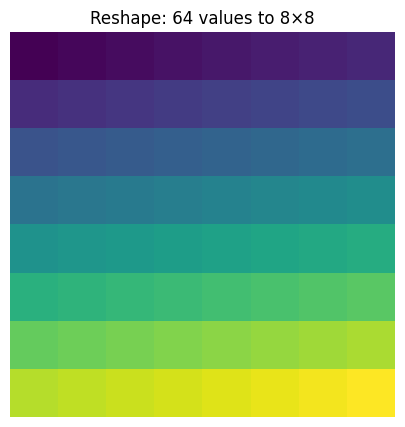

In [11]:
flat_pixels = np.arange(64)
image_8x8 = flat_pixels.reshape(8, 8)
print('flat shape:', flat_pixels.shape)
print('reshaped image shape:', image_8x8.shape)
plt.imshow(image_8x8, cmap='viridis')
plt.title('Reshape: 64 values to 8×8')
plt.axis('off')
plt.show()


### 2.2 Flatten

**Definition:** Flatten converts a multi-dimensional tensor into one long vector.

**Where used:** connecting image-like data to a dense layer, simple baseline models, converting CNN feature maps before classification in older architectures.

**Why needed:** dense layers expect vector-like input.

Example:

```text
8 × 8 image → 64 features
```

**Common mistake:** flattening too early before convolution. CNNs need spatial structure, so flattening raw images removes useful layout information.


In [12]:
image = np.arange(16).reshape(4, 4)
flat = image.flatten()
display(pd.DataFrame(image))
print('flattened:', flat)
print('flattened shape:', flat.shape)


,0,1,2,3
0,0,1,2,3
1,4,5,6,7
2,8,9,10,11
3,12,13,14,15


flattened: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15]
flattened shape: (16,)


### 2.3 Transpose

**Definition:** Transpose swaps axes.

For a matrix:

```text
(rows, columns) → (columns, rows)
```

**Where used:** changing image format, aligning matrix multiplication, converting between framework conventions such as NHWC and NCHW.

**Why needed:** operations like matrix multiplication require dimensions to align.

**Common mistake:** transposing data without updating the meaning of axes.


In [13]:
M = np.array([[1, 2, 3], [4, 5, 6]])
MT = M.T
print('M shape:', M.shape)
print('M.T shape:', MT.shape)
display(pd.DataFrame(M))
display(pd.DataFrame(MT))


M shape: (2, 3)
M.T shape: (3, 2)


,0,1,2
0,1,2,3
1,4,5,6


,0,1
0,1,4
1,2,5
2,3,6


### 2.4 Squeeze

**Definition:** Squeeze removes axes with size 1.

Example:

```text
(1, 28, 28, 1) → (28, 28)
```

**Where used:** cleaning model outputs, removing unnecessary singleton dimensions.

**Why needed:** some metrics or plotting functions expect lower-dimensional arrays.

**Common mistake:** removing the batch dimension accidentally when batch size is 1.


In [14]:
x = np.zeros((1, 28, 28, 1))
squeezed_all = np.squeeze(x)
squeezed_channel = np.squeeze(x, axis=-1)
print('original:', x.shape)
print('squeeze all singleton axes:', squeezed_all.shape)
print('squeeze channel axis only:', squeezed_channel.shape)


original: (1, 28, 28, 1)
squeeze all singleton axes: (28, 28)
squeeze channel axis only: (1, 28, 28)


### 2.5 Unsqueeze

**Definition:** Unsqueeze adds an axis with size 1.

In NumPy this is usually done with `np.expand_dims`.

Example:

```text
(28, 28) → (1, 28, 28)
```

**Where used:** adding batch dimension, adding channel dimension, preparing one sample for prediction.

**Why needed:** models usually expect input with batch dimension.

**Common mistake:** adding the new axis in the wrong position.


In [15]:
img = np.zeros((28, 28))
with_batch = np.expand_dims(img, axis=0)
with_channel = np.expand_dims(img, axis=-1)
with_batch_channel = np.expand_dims(with_channel, axis=0)

display(pd.DataFrame({
    'Object': ['img', 'with_batch', 'with_channel', 'with_batch_channel'],
    'Shape': [img.shape, with_batch.shape, with_channel.shape, with_batch_channel.shape]
}))


,Object,Shape
0,img,"(28, 28)"
1,with_batch,"(1, 28, 28)"
2,with_channel,"(28, 28, 1)"
3,with_batch_channel,"(1, 28, 28, 1)"


### 2.6 Concatenation

**Definition:** Concatenation joins tensors along an existing axis.

Examples:

```text
add more rows:     (2, 3) + (2, 3) → (4, 3)
add more features: (2, 3) + (2, 3) → (2, 6)
```

**Where used:** combining batches, joining features from different sources, multimodal models.

**Why needed:** many DL pipelines combine data from different branches or files.

**Common mistake:** concatenating along the wrong axis and mixing samples with features.


In [16]:
A = np.ones((2, 3))
B = np.zeros((2, 3))
concat_rows = np.concatenate([A, B], axis=0)
concat_features = np.concatenate([A, B], axis=1)

display(pd.DataFrame({
    'Operation': ['A', 'B', 'concat axis=0', 'concat axis=1'],
    'Shape': [A.shape, B.shape, concat_rows.shape, concat_features.shape],
    'Meaning': ['first matrix', 'second matrix', 'more rows/samples', 'more columns/features']
}))


,Operation,Shape,Meaning
0,A,"(2, 3)",first matrix
1,B,"(2, 3)",second matrix
2,concat axis=0,"(4, 3)",more rows/samples
3,concat axis=1,"(2, 6)",more columns/features


### 2.7 Stacking

**Definition:** Stacking joins tensors by creating a new axis.

Example:

```text
three images, each (28, 28)
stack → (3, 28, 28)
```

**Where used:** creating a batch from individual samples.

**Why needed:** training processes batches, and stacking is a clean way to create a batch axis.

**Common mistake:** using concatenation when stacking is needed. Concatenation does not create a new axis.


In [17]:
img1 = np.ones((4, 4))
img2 = np.zeros((4, 4))
img3 = np.full((4, 4), 2)
stacked = np.stack([img1, img2, img3], axis=0)
print('one image shape:', img1.shape)
print('stacked batch shape:', stacked.shape)


one image shape: (4, 4)
stacked batch shape: (3, 4, 4)


### 2.8 Shape Compatibility

**Definition:** Shapes are compatible when the operation rules allow them to work together.

For matrix multiplication:

```text
(m, n) @ (n, p) → (m, p)
```

For elementwise operations:

```text
same shape works
broadcastable shape may work
non-compatible shape fails
```

**Where used:** every forward pass and every loss calculation.

**Why needed:** most deep learning runtime errors are shape errors.

**Common mistake:** only checking total number of values instead of axis meaning.


In [18]:
compatibility = pd.DataFrame({
    'Operation': ['(4,3)+(4,3)', '(4,3)+(3,)', '(4,3)@(3,2)', '(4,3)@(4,2)'],
    'Works?': ['yes', 'yes', 'yes', 'no'],
    'Reason': ['same shape', 'broadcast over rows', 'inner dimensions match', 'inner dimensions do not match']
})
display(compatibility)


,Operation,Works?,Reason
0,"(4,3)+(4,3)",yes,same shape
1,"(4,3)+(3,)",yes,broadcast over rows
2,"(4,3)@(3,2)",yes,inner dimensions match
3,"(4,3)@(4,2)",no,inner dimensions do not match


## Step 3: Core Tensor Operations

Tensor operations are the calculations that happen inside neural-network layers. This step explains the operations used in neurons, layers, and bias addition.


### 3.1 Elementwise Addition and Subtraction

**Definition:** Elementwise addition/subtraction applies the operation to matching positions in two tensors.

Example:

```text
[1, 2, 3] + [10, 20, 30] = [11, 22, 33]
```

**Where used in DL:** residual connections, adding bias, adding noise, updating tensors.

**Why needed:** many layer operations combine tensors of the same shape.

**Common mistake:** trying elementwise operations on incompatible shapes without understanding broadcasting.


In [19]:
a = np.array([1, 2, 3])
b = np.array([10, 20, 30])
display(pd.DataFrame({'a':a, 'b':b, 'a+b':a+b, 'a-b':a-b}))


,a,b,a+b,a-b
0,1,10,11,-9
1,2,20,22,-18
2,3,30,33,-27


### 3.2 Elementwise Multiplication

**Definition:** Elementwise multiplication multiplies matching positions.

Example:

```text
[1, 2, 3] * [10, 20, 30] = [10, 40, 90]
```

**Where used in DL:** masks, attention masks, dropout masks, gates in LSTM/GRU, feature-wise scaling.

**Why needed:** sometimes the model needs to keep, suppress, or scale specific values.

**Common mistake:** confusing elementwise multiplication with matrix multiplication. Elementwise multiplication keeps the same shape; matrix multiplication changes shape according to linear algebra rules.


In [20]:
x = np.array([0.2, 0.7, 0.5, 0.9])
mask = np.array([1, 0, 1, 0])
display(pd.DataFrame({'x':x, 'mask':mask, 'x*mask':x*mask}))


,x,mask,x*mask
0,0.2,1,0.2
1,0.7,0,0.0
2,0.5,1,0.5
3,0.9,0,0.0


### 3.3 Dot Product

**Definition:** Dot product multiplies matching elements and adds them into one number.

Formula:

$$
x \cdot w = x_1w_1 + x_2w_2 + \dots + x_nw_n
$$

**Where used in DL:** one neuron calculation, attention score calculation, similarity calculations.

**Why needed:** a neuron needs to combine many input features into one weighted score.

**Simple DL meaning:** dot product answers, “How strongly do these inputs match these weights?”

**Common mistake:** forgetting that dot product returns one scalar, not a vector.


In [21]:
x = np.array([4.0, 2.0, 7.0])
w = np.array([0.8, 1.2, 0.3])
dot = np.dot(x, w)
display(pd.DataFrame({'input_x':x, 'weight_w':w, 'x*w':x*w}))
print('dot product:', dot)


,input_x,weight_w,x*w
0,4.0,0.8,3.2
1,2.0,1.2,2.4
2,7.0,0.3,2.1


dot product: 7.699999999999999


### 3.4 Matrix Multiplication

**Definition:** Matrix multiplication performs many dot products at once.

For a layer:

$$
Z = XW
$$

Shape rule:

```text
(batch, input_features) @ (input_features, output_neurons)
= (batch, output_neurons)
```

**Where used in DL:** dense layers, projections in attention, embedding transformations, output layers.

**Why needed:** layers process many samples and many neurons efficiently.

**Common mistake:** using `(input_features, batch)` instead of `(batch, input_features)`.


In [22]:
X = np.array([[1,2,3],[4,5,6]], dtype=float)
W = rng.normal(size=(3,4))
Z = X @ W
print('X shape:', X.shape)
print('W shape:', W.shape)
print('Z shape:', Z.shape)
display(pd.DataFrame(Z, columns=[f'neuron_{i}' for i in range(4)]).round(3))


X shape: (2, 3)
W shape: (3, 4)
Z shape: (2, 4)


,neuron_0,neuron_1,neuron_2,neuron_3
0,-3.648,-6.203,3.644,2.641
1,-8.637,-15.789,8.917,6.848


### 3.5 Bias Addition

**Definition:** Bias addition adds a learned bias value to each neuron output.

Layer formula:

$$
Z = XW + b
$$

**Where used in DL:** almost every dense/convolution layer has bias unless disabled.

**Why needed:** bias lets the model shift activation thresholds. Without bias, every neuron is forced to pass through the origin in its input-output relation.

**Simple intuition:** weights control feature importance; bias controls the baseline offset.

**Common mistake:** thinking bias is one number for the whole layer. Usually each output neuron has its own bias.


In [23]:
XW = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
b = np.array([0.5, -1.0, 2.0])
Z = XW + b
display(pd.DataFrame(XW, columns=['n1','n2','n3']))
print('bias:', b)
display(pd.DataFrame(Z, columns=['n1_plus_bias','n2_plus_bias','n3_plus_bias']))


,n1,n2,n3
0,1.0,2.0,3.0
1,4.0,5.0,6.0


bias: [ 0.5 -1.   2. ]


,n1_plus_bias,n2_plus_bias,n3_plus_bias
0,1.5,1.0,5.0
1,4.5,4.0,8.0


### 3.6 Broadcasting Rules

**Definition:** Broadcasting automatically expands smaller tensors so operations can happen with larger tensors.

Bias addition works because:

```text
XW shape: (batch, neurons)
b shape:  (neurons,)
```

The bias vector is broadcast across all rows.

**Where used in DL:** bias addition, normalization, scaling, masking.

**Why needed:** it avoids manually copying the same bias vector for every sample.

**Common mistake:** relying on broadcasting without checking which axis is being expanded.


In [24]:
XW = np.ones((4, 3))
b = np.array([10, 20, 30])
Z = XW + b
print('XW shape:', XW.shape)
print('b shape:', b.shape)
print('Z shape:', Z.shape)
display(pd.DataFrame(Z))


XW shape: (4, 3)
b shape: (3,)
Z shape: (4, 3)


,0,1,2
0,11.0,21.0,31.0
1,11.0,21.0,31.0
2,11.0,21.0,31.0
3,11.0,21.0,31.0


### 3.7 Common Broadcasting Mistakes

Broadcasting can silently produce the wrong result if the shape is valid but the meaning is wrong.

Example mistake:

```text
wanted: add one bias per feature
accidentally: add one bias per sample
```

Both might run if shapes align, but the model meaning changes.

**Rule:** before using broadcasting, say the axis meaning in words.

```text
Does this vector represent features, classes, channels, time steps, or samples?
```


In [25]:
X = np.ones((3, 4))
feature_bias = np.array([1, 2, 3, 4])      # correct: one per feature
sample_bias = np.array([[10], [20], [30]]) # different: one per sample

display(pd.DataFrame(X + feature_bias, columns=[f'f{i}' for i in range(4)]))
display(pd.DataFrame(X + sample_bias, columns=[f'f{i}' for i in range(4)]))
print('Both run, but they mean different things.')


,f0,f1,f2,f3
0,2.0,3.0,4.0,5.0
1,2.0,3.0,4.0,5.0
2,2.0,3.0,4.0,5.0


,f0,f1,f2,f3
0,11.0,11.0,11.0,11.0
1,21.0,21.0,21.0,21.0
2,31.0,31.0,31.0,31.0


Both run, but they mean different things.


## Step 4: Vector and Matrix Measurements

Measurements convert vectors or matrices into interpretable values such as size, distance, or similarity. These are used in regularization, embeddings, retrieval, anomaly detection, and optimization.


### 4.1 L1 Norm

**Definition:** L1 norm is the sum of absolute values.

Formula:

$$
\|x\|_1 = \sum_i |x_i|
$$

**Where used:** L1 regularization, sparse models, feature selection.

**Why needed:** L1 can encourage some weights to become exactly zero, which can make a model simpler.

**Example:**

```text
x = [3, -4, 2]
L1 = 3 + 4 + 2 = 9
```

**Common mistake:** thinking L1 and L2 regularization behave the same. L1 is more associated with sparsity.


In [26]:
v = np.array([3.0, -4.0, 2.0])
print('vector:', v)
print('L1 norm:', np.linalg.norm(v, ord=1))


vector: [ 3. -4.  2.]
L1 norm: 9.0


### 4.2 L2 Norm

**Definition:** L2 norm is the straight-line length of a vector.

Formula:

$$
\|x\|_2 = \sqrt{\sum_i x_i^2}
$$

**Where used:** weight decay, gradient clipping, Euclidean distance, embedding magnitude.

**Why needed:** L2 strongly penalizes large values because values are squared.

**Example:**

```text
x = [3, 4]
L2 = sqrt(3² + 4²) = 5
```

**Common mistake:** saying L2 removes features. L2 usually shrinks weights smoothly; it does not usually make them exactly zero.


L2 norm: 5.0


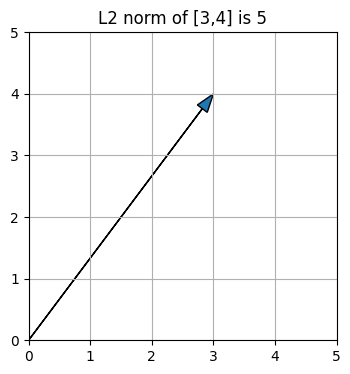

In [27]:
v = np.array([3.0, 4.0])
print('L2 norm:', np.linalg.norm(v, ord=2))
plt.figure(figsize=(4,4))
plt.arrow(0,0,v[0],v[1],head_width=.2,length_includes_head=True)
plt.xlim(0,5); plt.ylim(0,5); plt.gca().set_aspect('equal')
plt.title('L2 norm of [3,4] is 5')
plt.show()


### 4.3 Frobenius Norm

**Definition:** Frobenius norm is the L2-like size of a matrix.

Formula:

$$
\|A\|_F = \sqrt{\sum_i\sum_j A_{ij}^2}
$$

**Where used:** measuring weight matrix size, matrix reconstruction error, regularization.

**Why needed:** neural network layers store weights as matrices, so we need a way to measure the size of a whole matrix.

**Common mistake:** confusing Frobenius norm with matrix rank or determinant. It only measures size.


In [28]:
A = np.array([[1.0,2.0],[3.0,4.0]])
print('Frobenius norm:', np.linalg.norm(A, ord='fro'))
display(pd.DataFrame(A))


Frobenius norm: 5.477225575051661


,0,1
0,1.0,2.0
1,3.0,4.0


### 4.4 Euclidean Distance

**Definition:** Euclidean distance is the straight-line distance between two vectors.

Formula:

$$
d(a,b)=\sqrt{\sum_i(a_i-b_i)^2}
$$

**Where used:** nearest neighbors, clustering, anomaly detection, reconstruction error.

**Why needed:** it measures how far two points are in vector space.

**Common mistake:** using Euclidean distance on unscaled features. Large-scale features dominate.


In [29]:
a=np.array([1.0,2.0]); b=np.array([4.0,6.0])
print('Euclidean distance:', np.linalg.norm(a-b, ord=2))


Euclidean distance: 5.0


### 4.5 Manhattan Distance

**Definition:** Manhattan distance is the sum of absolute coordinate differences.

Formula:

$$
d(a,b)=\sum_i |a_i-b_i|
$$

**Where used:** robust distance comparisons, sparse data, nearest-neighbor variants.

**Why needed:** it measures axis-by-axis movement, like city blocks.

**Common mistake:** expecting Manhattan and Euclidean distance to always rank neighbors the same way.


In [30]:
a=np.array([1.0,2.0]); b=np.array([4.0,6.0])
print('Manhattan distance:', np.linalg.norm(a-b, ord=1))


Manhattan distance: 7.0


### 4.6 Cosine Similarity

**Definition:** Cosine similarity measures how much two vectors point in the same direction.

Formula:

$$
\cos(\theta)=\frac{a\cdot b}{\|a\|\|b\|}
$$

**Where used:** text embeddings, image embeddings, semantic search, recommendation systems.

**Why needed:** in embedding spaces, direction often matters more than vector size.

**Common mistake:** treating cosine similarity as a probability. It is an angle-based similarity score.


In [31]:
a=np.array([1.0,2.0]); b=np.array([10.0,20.0]); c=np.array([-2.0,1.0])
def cos(u,v): return np.dot(u,v)/(np.linalg.norm(u)*np.linalg.norm(v))
display(pd.DataFrame({'comparison':['a with b','a with c'], 'cosine_similarity':[cos(a,b), cos(a,c)]}).round(3))


,comparison,cosine_similarity
0,a with b,1.0
1,a with c,0.0


### 4.7 Vector Magnitude vs Direction

**Magnitude** means vector length. **Direction** means where the vector points.

Two vectors can have very different magnitudes but the same direction.

Example:

```text
[1, 2] and [10, 20]
```

The second is longer, but both point in the same direction.

**Where used:** embeddings and retrieval.

**Why needed:** cosine similarity focuses on direction, while Euclidean distance is affected by magnitude.

**Common mistake:** assuming close Euclidean distance and high cosine similarity always mean the same thing.


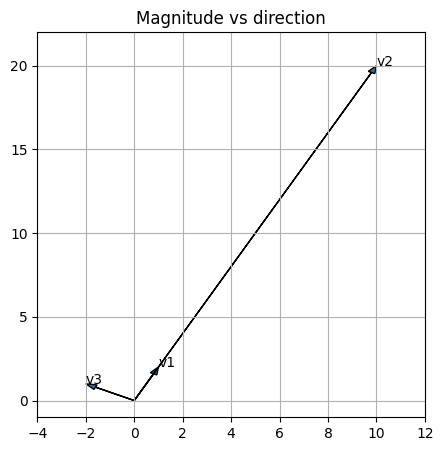

In [32]:
v1=np.array([1.0,2.0]); v2=np.array([10.0,20.0]); v3=np.array([-2.0,1.0])
plt.figure(figsize=(5,5))
for v,label in [(v1,'v1'),(v2,'v2'),(v3,'v3')]:
    plt.arrow(0,0,v[0],v[1],head_width=.3,length_includes_head=True)
    plt.text(v[0],v[1],label)
plt.xlim(-4,12); plt.ylim(-1,22); plt.title('Magnitude vs direction')
plt.show()


## Step 5: Derivatives and Gradients

Derivatives and gradients explain how a model learns. They tell the optimizer how a small parameter change affects loss.


### 5.1 Function

**Definition:** A function maps input to output.

Example:

$$
f(x)=x^2
$$

**Where used:** every layer, activation, and loss is a function.

**Why needed:** a neural network is a large composition of functions.

**Common mistake:** thinking functions are only formulas. In DL, a whole model is also a function from input tensor to output prediction.


### 5.2 Slope

**Definition:** Slope tells how steep a function is.

For a straight line:

```text
slope = change in y / change in x
```

**Where used:** derivative intuition.

**Why needed:** learning needs to know if increasing a weight increases or decreases loss.


### 5.3 Derivative and Local Slope

**Definition:** A derivative is the local slope of a function at one point.

For:

$$
f(x)=x^2
$$

Derivative:

$$
f'(x)=2x
$$

At $x=2$, slope is $4$.

**Where used:** optimizer updates and backpropagation.

**Common mistake:** thinking derivative is the same everywhere. It depends on the point.


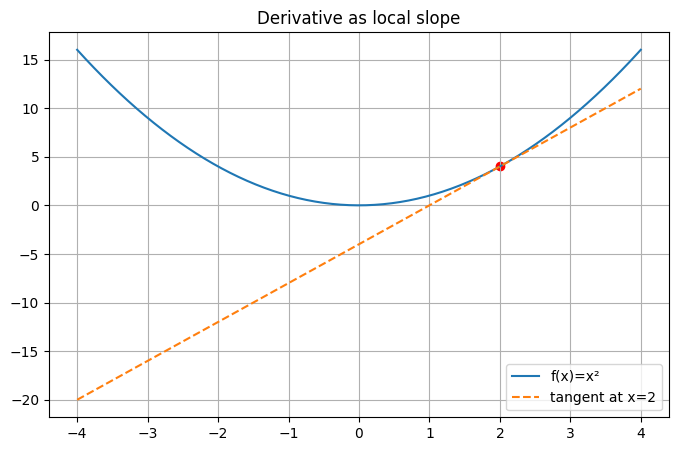

derivative at x=2: 4


In [33]:
x=np.linspace(-4,4,200); y=x**2; point=2; slope=2*point; tangent=point**2+slope*(x-point)
plt.plot(x,y,label='f(x)=x²'); plt.plot(x,tangent,'--',label='tangent at x=2'); plt.scatter([point],[point**2],color='red')
plt.legend(); plt.title('Derivative as local slope'); plt.show()
print('derivative at x=2:', slope)


### 5.4 Partial Derivative

**Definition:** A partial derivative measures change with respect to one variable while holding other variables fixed.

Example:

$$
f(x,y)=x^2+3y
$$

$$
\frac{\partial f}{\partial x}=2x
$$

$$
\frac{\partial f}{\partial y}=3
$$

**Where used:** loss changes with respect to each weight.

**Why needed:** neural networks have many parameters, so we need one derivative per parameter.

**Common mistake:** thinking one derivative is enough for a full model.


In [34]:
x_val=2.0; y_val=5.0
f=x_val**2+3*y_val
df_dx=2*x_val; df_dy=3
display(pd.DataFrame({'quantity':['f(x,y)','partial df/dx','partial df/dy'], 'value':[f,df_dx,df_dy]}))


,quantity,value
0,"f(x,y)",19.0
1,partial df/dx,4.0
2,partial df/dy,3.0


### 5.5 Gradient Vector

**Definition:** The gradient vector collects all partial derivatives.

For:

$$
L=L(w_1,w_2,w_3)
$$

$$
\nabla L=\left[\frac{\partial L}{\partial w_1},\frac{\partial L}{\partial w_2},\frac{\partial L}{\partial w_3}\right]
$$

**Where used:** gradient descent, SGD, Adam, backpropagation.

**Why needed:** it tells how to change all parameters.

**Common mistake:** gradient points uphill for loss; to reduce loss, move in the negative gradient direction.


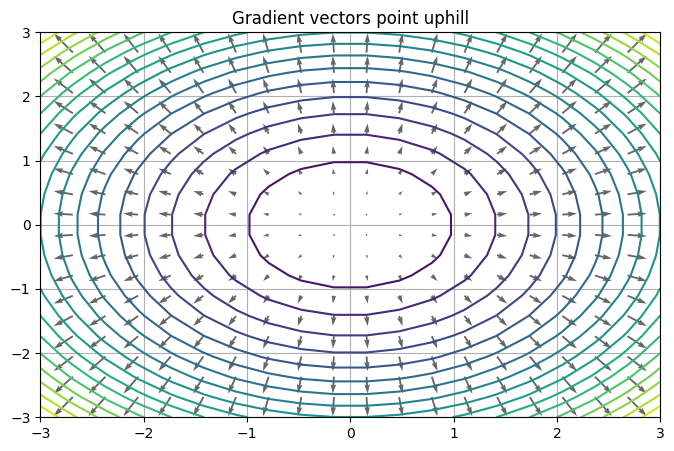

In [35]:
xg,yg=np.meshgrid(np.linspace(-3,3,20),np.linspace(-3,3,20)); z=xg**2+yg**2; gx=2*xg; gy=2*yg
plt.contour(xg,yg,z,levels=20); plt.quiver(xg,yg,gx,gy,alpha=.6); plt.title('Gradient vectors point uphill'); plt.show()


### 5.6 Negative-Gradient Direction

**Definition:** The negative-gradient direction is the direction that reduces the loss fastest locally.

Update rule:

$$
w_{new}=w_{old}-\eta\nabla L(w)
$$

**Where used:** all first-order optimizers.

**Why needed:** training is repeated movement in directions that reduce loss.

**Common mistake:** using too large a learning rate and jumping past the minimum.


### 5.7 Gradient Descent Update

**Definition:** Gradient descent update changes parameters using the negative gradient.

Formula:

$$
w_{new}=w_{old}-\eta\frac{\partial L}{\partial w}
$$

**Where used:** SGD, mini-batch gradient descent, Adam-style optimizers.

**Why needed:** this is how a model learns from loss.


,step,w,loss,gradient
0,0,-4.000,49.000,-14.000
1,1,-1.200,17.640,-8.400
2,2,0.480,6.350,-5.040
3,3,1.488,2.286,-3.024
4,4,2.093,0.823,-1.814
5,5,2.456,0.296,-1.089
6,6,2.673,0.107,-0.653
7,7,2.804,0.038,-0.392
8,8,2.882,0.014,-0.235
9,9,2.929,0.005,-0.141


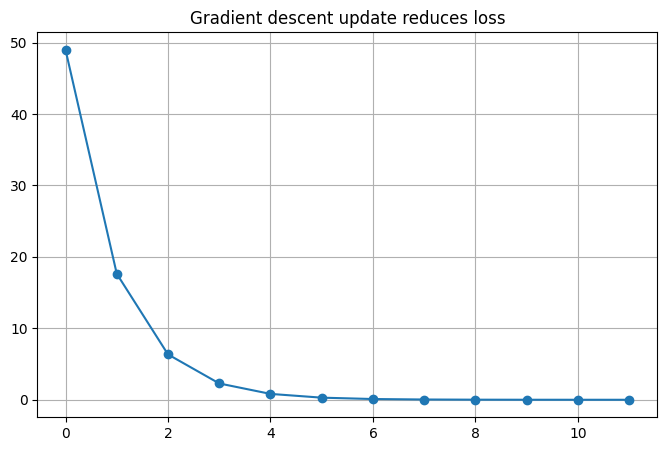

In [36]:
def loss(w): return (w-3)**2
def grad(w): return 2*(w-3)
w=-4.0; lr=.2; rows=[]
for step in range(12):
    rows.append({'step':step,'w':w,'loss':loss(w),'gradient':grad(w)})
    w = w - lr*grad(w)
df=pd.DataFrame(rows); display(df.round(3)); plt.plot(df.step,df.loss,marker='o'); plt.title('Gradient descent update reduces loss'); plt.show()


## Step 6: Chain Rule and Backpropagation Math

Deep networks are nested functions.

Example:

$$
y = f(g(x))
$$

The chain rule says:

$$
\frac{dy}{dx} = \frac{dy}{dg} \cdot \frac{dg}{dx}
$$

Why it matters:

Backpropagation uses the chain rule to pass gradients backward through layers.

Deep learning connection:

```text
input → layer 1 → activation → layer 2 → loss
```

To update layer 1 weights, the model must know how layer 1 affected the final loss. That requires the chain rule.


### Why Chain Rule Is the Heart of Backpropagation

A deep network is a chain of functions.

```text
input → layer 1 → activation → layer 2 → activation → output → loss
```

The first layer affects the loss indirectly through every later layer. The chain rule tells us how to measure that indirect effect.

Without chain rule, we could update only the final layer easily, but not earlier layers.

Backpropagation is basically the chain rule applied efficiently from the loss backward through the network.

**Common mistake:** memorizing the chain rule formula without connecting it to layers. Think of it as “how much did this earlier value influence the final loss through all later steps?”


In [37]:
# y = (3x + 2)^2
x = 4.0
g = 3*x + 2
y = g**2
# dy/dx = dy/dg * dg/dx = 2g * 3
dy_dx = 2*g*3

print('x:', x)
print('g = 3x + 2:', g)
print('y = g²:', y)
print('dy/dx using chain rule:', dy_dx)


x: 4.0
g = 3x + 2: 14.0
y = g²: 196.0
dy/dx using chain rule: 84.0


### Jacobian Intuition

A derivative of one output with respect to one input is a number.

But many deep learning operations have many inputs and many outputs.

The **Jacobian** stores all first-order partial derivatives for a vector-output function.

If:

```text
input vector has 2 values
output vector has 3 values
```

Then the Jacobian shape is:

```text
(3 outputs, 2 inputs)
```

Where used:

- understanding vector-valued functions
- backpropagation theory
- sensitivity analysis
- advanced optimization

Most frameworks do not explicitly build the full Jacobian for every layer because it would be huge. They use efficient vector-Jacobian products.


In [38]:
# Function: f([x,y]) = [x+y, x*y, x^2]
x, y = 2.0, 3.0
J = np.array([
    [1, 1],      # d(x+y)/dx, d(x+y)/dy
    [y, x],      # d(x*y)/dx, d(x*y)/dy
    [2*x, 0],    # d(x^2)/dx, d(x^2)/dy
])
display(pd.DataFrame(J, columns=['d/dx', 'd/dy'], index=['x+y', 'x*y', 'x^2']))
print('Jacobian shape:', J.shape)


,d/dx,d/dy
x+y,1.0,1.0
x*y,3.0,2.0
x^2,4.0,0.0


Jacobian shape: (3, 2)


### Hessian and Curvature Intuition

The **Hessian** contains second-order derivatives.

First derivative tells slope.

Second derivative tells curvature.

Where used:

- understanding optimization difficulty
- Newton-style methods
- saddle points
- curvature analysis

Deep learning usually uses first-order methods like SGD/Adam because the Hessian is too expensive for large networks. But curvature intuition helps explain why optimization can be hard.


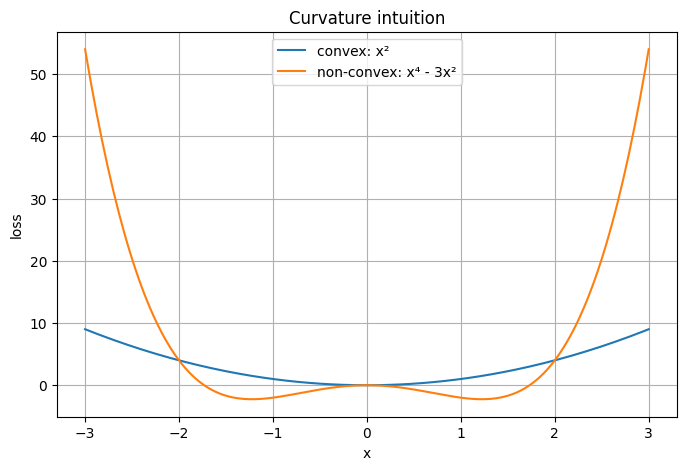

In [39]:
x = np.linspace(-3, 3, 200)
convex = x**2
nonconvex = x**4 - 3*x**2

plt.plot(x, convex, label='convex: x²')
plt.plot(x, nonconvex, label='non-convex: x⁴ - 3x²')
plt.title('Curvature intuition')
plt.xlabel('x')
plt.ylabel('loss')
plt.legend()
plt.show()


## Step 7: Probability Foundations for DL Losses

For classification, neural networks often output probabilities.

Probability rules:

- probabilities are between 0 and 1
- probabilities over all classes sum to 1 for multiclass classification

Example:

```text
P(cat) = 0.70
P(dog) = 0.20
P(rabbit) = 0.10
```

The model predicts the class with the highest probability, but the loss uses the probability assigned to the true class.


In [40]:
probs = np.array([0.7, 0.2, 0.1])
classes = ['cat', 'dog', 'rabbit']
display(pd.DataFrame({'class': classes, 'probability': probs}))
print('Sum of probabilities:', probs.sum())
print('Predicted class:', classes[np.argmax(probs)])


,class,probability
0,cat,0.7
1,dog,0.2
2,rabbit,0.1


Sum of probabilities: 0.9999999999999999
Predicted class: cat


### Likelihood and Log-Likelihood

**Likelihood** measures how much probability the model assigns to the observed correct labels.

If the true class is `cat`, and the model assigns:

```text
P(cat)=0.70
```

then the likelihood for that example is `0.70`.

For many examples, likelihood multiplies probabilities. Multiplying many small numbers can underflow, so we usually use log-likelihood.

Log-likelihood turns multiplication into addition:

$$
\log(a \times b) = \log(a) + \log(b)
$$

Loss functions often minimize **negative log-likelihood**.


In [41]:
true_class_probs = np.array([0.8, 0.6, 0.9, 0.7])
likelihood = np.prod(true_class_probs)
log_likelihood = np.sum(np.log(true_class_probs))
negative_log_likelihood = -log_likelihood

display(pd.DataFrame({
    'Quantity': ['likelihood product', 'log-likelihood sum', 'negative log-likelihood'],
    'Value': [likelihood, log_likelihood, negative_log_likelihood]
}).round(4))


,Quantity,Value
0,likelihood product,0.3024
1,log-likelihood sum,-1.1960
2,negative log-likelihood,1.1960


## Step 8: Information-Theoretic Loss Concepts

Entropy measures uncertainty in a probability distribution.

Formula:

$$
H(p) = -\sum_i p_i \log(p_i)
$$

Low entropy:

```text
[0.99, 0.01]
```

High entropy:

```text
[0.50, 0.50]
```

Where used:

- uncertainty measurement
- decision trees / information gain
- classification loss intuition
- reinforcement learning exploration
- generative modeling


### Entropy as Uncertainty

Entropy measures uncertainty in a distribution.

If a model says:

```text
[1.0, 0.0, 0.0]
```

there is no uncertainty. The model is fully concentrated on one class.

If a model says:

```text
[0.33, 0.33, 0.34]
```

there is high uncertainty. The probability is spread across classes.

**Where used in DL:** classification uncertainty, active learning, reinforcement learning exploration, information theory, decision trees, generative modeling.

**Common mistake:** thinking entropy means error. Entropy is uncertainty, not correctness. A model can be confidently wrong with low entropy.


,distribution,probabilities,entropy_bits
0,very confident,"[0.99, 0.01]",0.081
1,moderately confident,"[0.75, 0.25]",0.811
2,uncertain,"[0.5, 0.5]",1.000


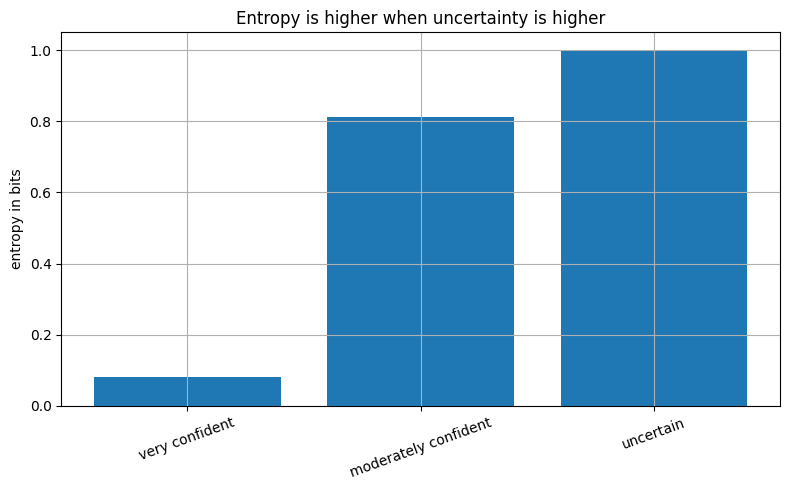

In [42]:
def entropy(p):
    p = np.array(p)
    return -np.sum(p * np.log2(p + 1e-12))

dists = {
    'very confident': [0.99, 0.01],
    'moderately confident': [0.75, 0.25],
    'uncertain': [0.5, 0.5]
}
rows = [{'distribution': k, 'probabilities': v, 'entropy_bits': entropy(v)} for k, v in dists.items()]
display(pd.DataFrame(rows).round(3))

plt.bar(dists.keys(), [entropy(v) for v in dists.values()])
plt.ylabel('entropy in bits')
plt.title('Entropy is higher when uncertainty is higher')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Cross-Entropy

Cross-entropy measures how well a predicted distribution matches the true distribution.

Formula:

$$
H(p,q) = -\sum_i p_i \log(q_i)
$$

Where:

- $p$ = true distribution
- $q$ = predicted distribution

For one-hot labels, cross-entropy becomes:

```text
-negative log probability of the true class
```

This is why wrong confident predictions are punished strongly.


### Cross-Entropy as Classification Loss

Cross-entropy compares the true label distribution with the predicted distribution.

For one-hot labels, it focuses on the probability assigned to the correct class.

Example:

```text
true class = cat
model gives P(cat) = 0.90 → small loss
model gives P(cat) = 0.05 → large loss
```

This is why cross-entropy is used for classification. It does not only ask “was the final class correct?” It asks “how much probability did you assign to the correct class?”

**Common mistake:** applying softmax twice before cross-entropy. Many frameworks have a loss function that expects raw logits and applies stable softmax internally.


In [43]:
y_true = np.array([1, 0, 0])
good_pred = np.array([0.9, 0.08, 0.02])
okay_pred = np.array([0.6, 0.3, 0.1])
bad_pred = np.array([0.05, 0.15, 0.8])

def cross_entropy(p, q):
    return -np.sum(p * np.log(q + 1e-12))

rows = []
for name, q in [('good', good_pred), ('okay', okay_pred), ('bad', bad_pred)]:
    rows.append({'prediction': name, 'true_class_probability': q[0], 'cross_entropy_loss': cross_entropy(y_true, q)})
display(pd.DataFrame(rows).round(3))


,prediction,true_class_probability,cross_entropy_loss
0,good,0.90,0.105
1,okay,0.60,0.511
2,bad,0.05,2.996


### Output Meaning

The good prediction gives high probability to the true class, so the loss is small.

The bad prediction gives low probability to the true class, so the loss is large.

Common mistake: thinking cross-entropy checks only whether the final predicted class is correct. It also cares how much probability the model assigned to the correct class.


### KL Divergence

KL divergence measures how different one probability distribution is from another.

Formula:

$$
D_{KL}(P || Q) = \sum_i P_i \log\left(\frac{P_i}{Q_i}\right)
$$

Where used in deep learning:

- VAEs: keep latent distribution close to a normal distribution
- knowledge distillation: student distribution compared with teacher distribution
- reinforcement learning policy updates
- distribution shift analysis

Important: KL divergence is not symmetric.

```text
KL(P || Q) is not always equal to KL(Q || P)
```


### KL Divergence as Distribution Difference

KL divergence compares two probability distributions.

It answers:

```text
If P is the true/reference distribution, how inefficient is it to use Q instead?
```

This is deeper than ordinary distance because distributions have probability meaning.

**Where it appears in deep learning:**

- **VAE:** keeps learned latent distribution close to a simple prior distribution.
- **Knowledge distillation:** student model learns to match teacher model probabilities.
- **RL:** limits how much a new policy changes from an old policy.
- **Monitoring:** compares current prediction distribution against past distribution.

**Common mistake:** treating KL divergence like normal distance. KL is not symmetric and does not behave like Euclidean distance.


In [44]:
def kl(p, q):
    p = np.array(p)
    q = np.array(q)
    return np.sum(p * np.log((p + 1e-12) / (q + 1e-12)))

P = np.array([0.7, 0.2, 0.1])
Q = np.array([0.6, 0.3, 0.1])
R = np.array([0.1, 0.2, 0.7])

display(pd.DataFrame({
    'Comparison': ['KL(P || Q)', 'KL(Q || P)', 'KL(P || R)'],
    'Value': [kl(P, Q), kl(Q, P), kl(P, R)]
}).round(4))


,Comparison,Value
0,KL(P || Q),0.0268
1,KL(Q || P),0.0291
2,KL(P || R),1.1675


### Output Meaning

`P` and `Q` are similar, so KL is small.

`P` and `R` are very different, so KL is larger.

This idea appears later in VAEs and model distillation.


## Step 9: Numerical Stability

Deep learning uses exponential, logarithm, division, and repeated multiplication. These operations can cause numerical problems.

Common problems:

| Problem | Meaning | Example |
|---|---|---|
| Overflow | number becomes too large | `exp(1000)` |
| Underflow | number becomes too close to zero | multiplying many tiny probabilities |
| log(0) | undefined | `log(0)` gives `-inf` |
| division by zero | undefined | normalization with zero denominator |

Stable implementations avoid these problems.


### Why Numerical Stability Is a Real Deep Learning Problem

Computers cannot represent all real numbers perfectly. Deep learning repeatedly applies exponentials, logarithms, divisions, and matrix operations. Small numerical issues can become big training failures.

Examples:

```text
exp(1000) → too large → overflow
log(0)   → undefined → -inf
0 / 0    → undefined → nan
```

Once `nan` appears in loss or gradients, training often becomes unusable.

**Common places this happens:** softmax, cross-entropy, normalization, very high learning rate, exploding gradients, mixed precision training.

**Common mistake:** assuming a formula that is mathematically correct is automatically safe in code. Stable implementations often rewrite the same formula to avoid overflow/underflow.


In [45]:
values = np.array([10, 100, 1000], dtype=np.float64)
rows = []
for v in values:
    try:
        ev = np.exp(v)
    except Exception as e:
        ev = str(e)
    rows.append({'x': v, 'exp(x)': ev})
display(pd.DataFrame(rows))

print('log(0) without epsilon:', np.log(0))
print('log(0 + 1e-12) with epsilon:', np.log(1e-12))


C:\Users\91832\AppData\Local\Temp\ipykernel_13284\1738317693.py:5: RuntimeWarning: overflow encountered in exp
  ev = np.exp(v)


,x,exp(x)
0,10.0,2.202647e+04
1,100.0,2.688117e+43
2,1000.0,inf


log(0) without epsilon: -inf
log(0 + 1e-12) with epsilon: -27.631021115928547


C:\Users\91832\AppData\Local\Temp\ipykernel_13284\1738317693.py:11: RuntimeWarning: divide by zero encountered in log
  print('log(0) without epsilon:', np.log(0))


### Stable Softmax and Log-Sum-Exp

Softmax formula:

$$
\text{softmax}(z_i)=\frac{e^{z_i}}{\sum_j e^{z_j}}
$$

Problem: if logits are large, `exp(logit)` can overflow.

Stable trick: subtract the maximum logit before exponentiating.

$$
\text{softmax}(z_i)=\frac{e^{z_i - \max(z)}}{\sum_j e^{z_j - \max(z)}}
$$

This does not change the final probabilities, but it prevents overflow.


### Why Stable Softmax Works

Softmax uses exponentials:

$$
\frac{e^{z_i}}{\sum_j e^{z_j}}
$$

If logits are huge, exponentials overflow. But softmax is unchanged if we subtract the same constant from every logit.

So we subtract the maximum logit:

```text
[1000, 999, 998] → [0, -1, -2]
```

The probabilities stay the same, but exponentials become safe.

**Common mistake:** implementing softmax manually without subtracting the maximum. In real DL code, use framework-provided stable softmax/cross-entropy functions.


In [46]:
def softmax_unstable(z):
    ez = np.exp(z)
    return ez / ez.sum()

def softmax_stable(z):
    shifted = z - np.max(z)
    ez = np.exp(shifted)
    return ez / ez.sum()

small_logits = np.array([2.0, 1.0, 0.1])
large_logits = np.array([1000.0, 999.0, 998.0])

print('Stable softmax small logits:', softmax_stable(small_logits))
print('Stable softmax large logits:', softmax_stable(large_logits))
try:
    print('Unstable softmax large logits:', softmax_unstable(large_logits))
except Exception as e:
    print('Unstable softmax failed:', e)


Stable softmax small logits: [0.65900114 0.24243297 0.09856589]
Stable softmax large logits: [0.66524096 0.24472847 0.09003057]
Unstable softmax large logits: [nan nan nan]


C:\Users\91832\AppData\Local\Temp\ipykernel_13284\2521976929.py:2: RuntimeWarning: overflow encountered in exp
  ez = np.exp(z)
C:\Users\91832\AppData\Local\Temp\ipykernel_13284\2521976929.py:3: RuntimeWarning: invalid value encountered in divide
  return ez / ez.sum()


### Log-Sum-Exp Idea

Log-sum-exp is a stable way to compute:

$$
\log\left(\sum_i e^{x_i}\right)
$$

Stable form:

$$
\log\left(\sum_i e^{x_i}\right) = m + \log\left(\sum_i e^{x_i-m}\right)
$$

where:

$$
m = \max(x)
$$

This idea appears inside stable softmax and cross-entropy implementations.


In [47]:
def logsumexp_stable(x):
    m = np.max(x)
    return m + np.log(np.sum(np.exp(x - m)))

x = np.array([1000.0, 999.0, 998.0])
print('stable logsumexp:', logsumexp_stable(x))


stable logsumexp: 1000.4076059644444


## Step 10: Deep Learning Math Mistakes Checklist

| Mistake | Why it causes problems |
|---|---|
| Ignoring tensor shapes | matrix multiplication fails or silently gives wrong interpretation |
| Confusing rows and columns | features and samples get swapped |
| Forgetting batch dimension | model receives wrong input shape |
| Using elementwise multiply instead of dot product | neuron calculation becomes wrong |
| Trusting broadcasting blindly | wrong axis can be broadcast silently |
| Using unstable softmax | overflow creates `nan` or invalid probabilities |
| Taking `log(0)` | creates `-inf` loss |
| Mixing logits and probabilities | loss function may be used incorrectly |
| Confusing entropy and cross-entropy | uncertainty vs prediction loss are different ideas |
| Assuming KL divergence is symmetric | `KL(P||Q)` and `KL(Q||P)` can differ |


## Final Checklist

Before moving to Module 3, you should be able to answer:

- What is the difference between scalar, vector, matrix, and tensor?
- What do shape, axis, rank, and dtype mean?
- Why is the batch dimension important?
- What do squeeze and unsqueeze do?
- What is the difference between concatenation and stacking?
- How do you check shape compatibility?
- How does a dot product relate to one neuron?
- How does matrix multiplication relate to one layer?
- Why is broadcasting used for bias addition?
- What is the difference between L1 and L2 norm?
- What is Manhattan distance?
- What is the difference between vector magnitude and direction?
- Why is cosine similarity useful for embeddings?
- What does a derivative measure?
- What is a partial derivative?
- What is a gradient vector?
- Why does gradient descent move in the negative gradient direction?
- Why is the chain rule necessary for backpropagation?
- What are Jacobian and Hessian used to understand?
- What is likelihood?
- Why do we use log-likelihood?
- What does entropy measure?
- What does cross-entropy measure?
- What does KL divergence compare?
- Why can softmax overflow?
- How does stable softmax fix overflow?

Next module: **Neurons, Perceptrons, and Multilayer Perceptrons**.
